In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/bilalahmad302/burj-khalifa-feature-detection-dataset/pic 1.jpg
/kaggle/input/datasets/bilalahmad302/burj-khalifa-feature-detection-dataset/pic 2.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_1.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_106.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_109.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_113.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_114.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_116.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_118.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats/cat_119.jpg
/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-cla

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:

import os

dataset_path = "/kaggle/input/datasets/bilalahmad302/burj-khalifa-feature-detection-dataset"

print("Dataset files:")

for file in os.listdir(dataset_path):
    print(file)


Dataset files:
pic 1.jpg
pic 2.jpg


In [4]:

import os

dataset_path = "/kaggle/input/datasets/bilalahmad302/burj-khalifa-feature-detection-dataset"

print("Checking dataset...")

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)

    for file in files:
        print("File:", file)


Checking dataset...

Folder: /kaggle/input/datasets/bilalahmad302/burj-khalifa-feature-detection-dataset
File: pic 1.jpg
File: pic 2.jpg


Image 1 loaded: True
Image 2 loaded: True


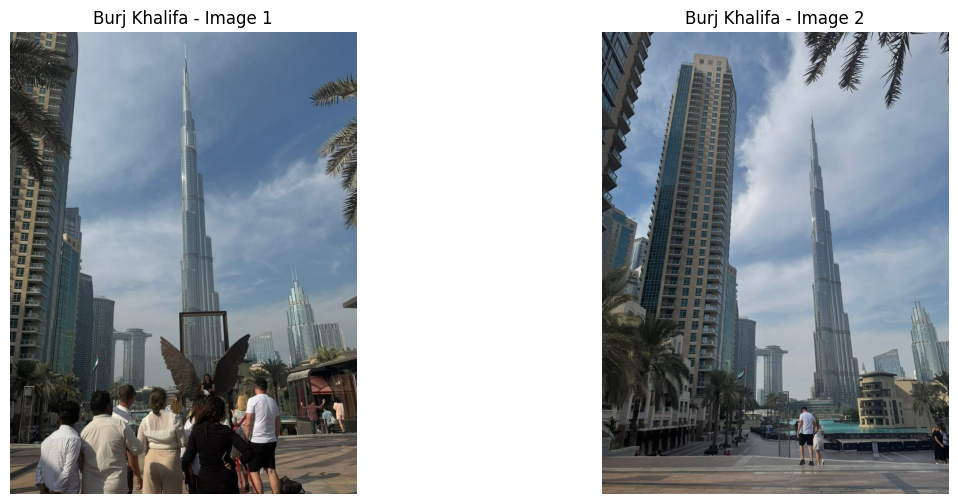

In [5]:

import cv2
import matplotlib.pyplot as plt
import os

dataset_path = "/kaggle/input/datasets/bilalahmad302/burj-khalifa-feature-detection-dataset"

# Load images using actual filenames
img1 = cv2.imread(os.path.join(dataset_path, "pic 1.jpg"))
img2 = cv2.imread(os.path.join(dataset_path, "pic 2.jpg"))

print("Image 1 loaded:", img1 is not None)
print("Image 2 loaded:", img2 is not None)

# Display images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Burj Khalifa - Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.title("Burj Khalifa - Image 2")
plt.axis("off")

plt.show()


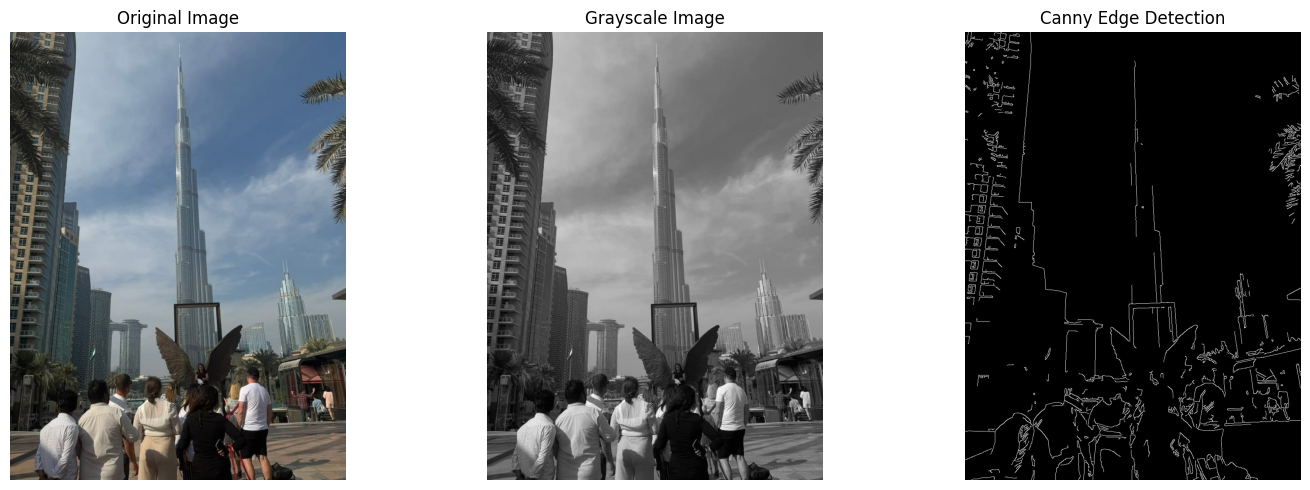

Canny Edge Detection completed successfully!


In [6]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Use the first loaded image
image = img1

# Step 2: Convert image into grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Step 3: Apply Gaussian Blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 4: Apply Canny Edge Detection
edges = cv2.Canny(blur, 100, 200)

# Step 5: Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite("/kaggle/working/edge_detection.png", edges)

print("Canny Edge Detection completed successfully!")

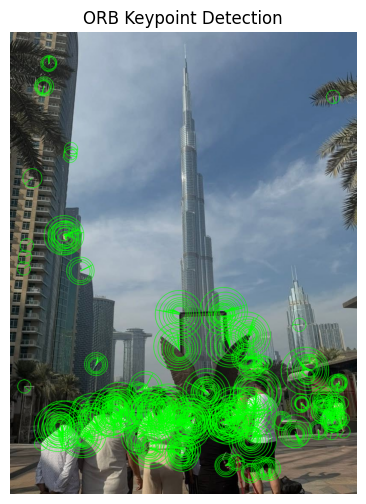

Total Keypoints: 500
Descriptor Shape: (500, 32)


True

In [7]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Convert first image to grayscale
gray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

# Step 2: Create ORB detector
orb = cv2.ORB_create(nfeatures=500)

# Step 3: Detect keypoints and calculate descriptors
keypoints, descriptors = orb.detectAndCompute(gray, None)

# Step 4: Draw keypoints on the original image
output = cv2.drawKeypoints(
    img1,
    keypoints,
    None,
    color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Step 5: Display result
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("ORB Keypoint Detection")
plt.axis("off")
plt.show()

# Step 6: Display information
print("Total Keypoints:", len(keypoints))

if descriptors is not None:
    print("Descriptor Shape:", descriptors.shape)
else:
    print("No descriptors found.")

# Save output
cv2.imwrite("/kaggle/working/orb_keypoints.png", output)

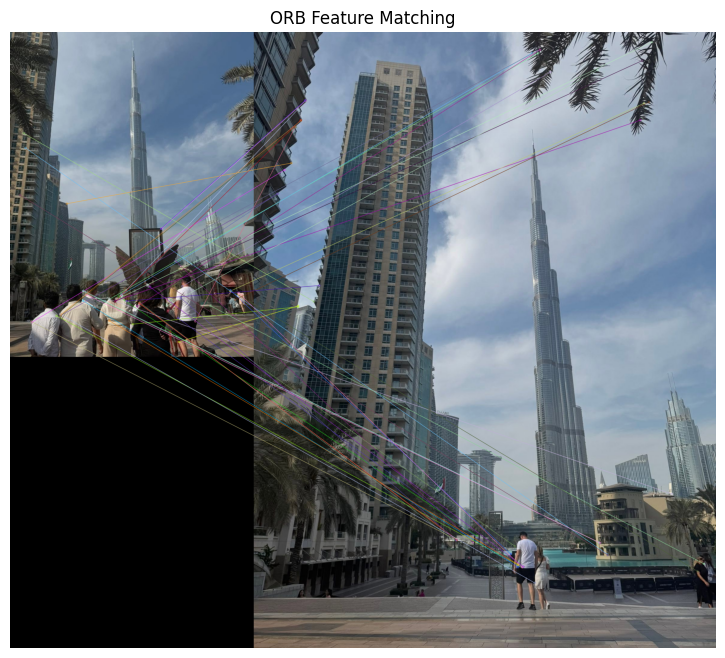

Keypoints in Image 1: 1000
Keypoints in Image 2: 1000
Total Matches: 239


True

In [8]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Convert both images to grayscale
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Step 2: Create ORB detector
orb = cv2.ORB_create(nfeatures=1000)

# Step 3: Detect keypoints and descriptors
kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

# Step 4: Create Brute Force Matcher
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Step 5: Match descriptors
matches = bf.match(des1, des2)

# Step 6: Sort matches by distance
matches = sorted(matches, key=lambda x: x.distance)

# Step 7: Draw best 50 matches
matching_result = cv2.drawMatches(
    img1, kp1,
    img2, kp2,
    matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Step 8: Display result
plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matching_result, cv2.COLOR_BGR2RGB))
plt.title("ORB Feature Matching")
plt.axis("off")
plt.show()

# Step 9: Print results
print("Keypoints in Image 1:", len(kp1))
print("Keypoints in Image 2:", len(kp2))
print("Total Matches:", len(matches))

# Save output
cv2.imwrite("/kaggle/working/orb_feature_matching.png", matching_result)

In [9]:
import os

dataset_path = "/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification"

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Number of images:", len(files))
    print("Sample files:", files[:5])


Folder: /kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification
Subfolders: ['test', 'train']
Number of images: 0
Sample files: []

Folder: /kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test
Subfolders: ['cats', 'dogs']
Number of images: 0
Sample files: []

Folder: /kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/cats
Subfolders: []
Number of images: 70
Sample files: ['cat_1.jpg', 'cat_106.jpg', 'cat_109.jpg', 'cat_113.jpg', 'cat_114.jpg']

Folder: /kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/test/dogs
Subfolders: []
Number of images: 70
Sample files: ['dog_114.jpg', 'dog_123.jpg', 'dog_124.jpg', 'dog_130.jpg', 'dog_141.jpg']

Folder: /kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/train
Subfolders: ['cats', 'dogs']
Number of images: 0
Sample files: []

Folder: /kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification/train/cats
Subfolders:

In [10]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import MiniBatchKMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [11]:
dataset_path = "/kaggle/input/datasets/samuelcortinhas/cats-and-dogs-image-classification"

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print("Dataset paths loaded successfully!")

Dataset paths loaded successfully!


In [12]:
def load_images(folder):
    images = []
    labels = []

    for category in ["cats", "dogs"]:
        category_path = os.path.join(folder, category)

        for filename in os.listdir(category_path):
            image_path = os.path.join(category_path, filename)

            image = cv2.imread(image_path)

            if image is not None:
                image = cv2.resize(image, (128, 128))
                images.append(image)
                labels.append(category)

    return images, labels


X_train_images, y_train = load_images(train_path)
X_test_images, y_test = load_images(test_path)

print("Training images:", len(X_train_images))
print("Testing images:", len(X_test_images))

Training images: 557
Testing images: 140


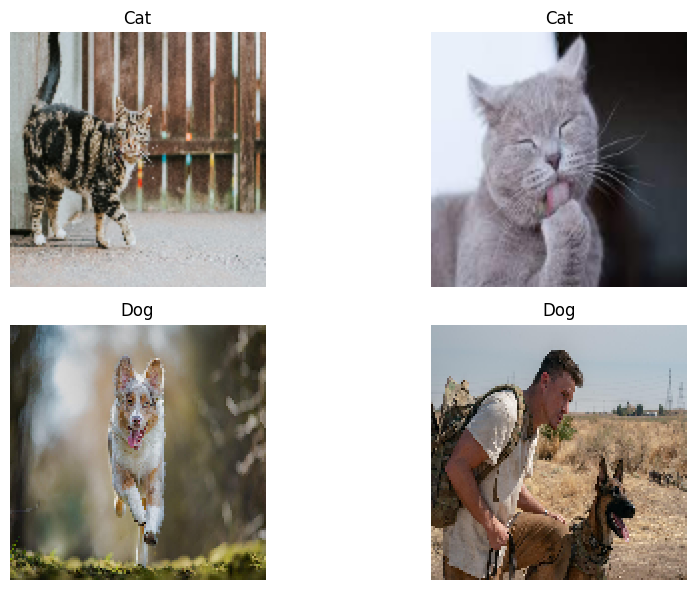

In [13]:
plt.figure(figsize=(10, 6))

# Display 2 cat images
for i in range(2):
    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(X_train_images[i], cv2.COLOR_BGR2RGB))
    plt.title("Cat")
    plt.axis("off")

# Display 2 dog images
for i in range(2):
    plt.subplot(2, 2, i + 3)
    dog_index = 279 + i
    plt.imshow(cv2.cvtColor(X_train_images[dog_index], cv2.COLOR_BGR2RGB))
    plt.title("Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Create ORB detector
orb = cv2.ORB_create(nfeatures=500)

# Function to extract ORB descriptors
def extract_orb_features(images):

    all_descriptors = []

    for image in images:

        # Convert image to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Detect keypoints and descriptors
        keypoints, descriptors = orb.detectAndCompute(gray, None)

        if descriptors is not None:
            all_descriptors.append(descriptors)

    return all_descriptors


# Extract features from training images
train_descriptors = extract_orb_features(X_train_images)

# Extract features from testing images
test_descriptors = extract_orb_features(X_test_images)

print("Training images processed:", len(train_descriptors))
print("Testing images processed:", len(test_descriptors))

Training images processed: 557
Testing images processed: 140


In [15]:
# Combine all training descriptors
all_descriptors = np.vstack(train_descriptors)

print("Combined descriptors shape:", all_descriptors.shape)

Combined descriptors shape: (105642, 32)


In [16]:
# Number of visual words
K = 50

# Create K-Means model
kmeans = MiniBatchKMeans(
    n_clusters=K,
    random_state=42,
    batch_size=100
)

# Train K-Means on ORB descriptors
kmeans.fit(all_descriptors)

print("BoVW vocabulary created successfully!")

BoVW vocabulary created successfully!


In [17]:
def create_bovw_features(descriptor_list, kmeans, K):

    features = []

    for descriptors in descriptor_list:

        # Assign each descriptor to a visual word
        visual_words = kmeans.predict(descriptors)

        # Create histogram of visual words
        histogram = np.bincount(visual_words, minlength=K)

        # Add histogram to feature list
        features.append(histogram)

    return np.array(features)


# Convert training descriptors into BoVW features
X_train = create_bovw_features(train_descriptors, kmeans, K)

# Convert testing descriptors into BoVW features
X_test = create_bovw_features(test_descriptors, kmeans, K)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (557, 50)
Testing feature shape: (140, 50)


In [18]:
# Create k-NN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

print("k-NN model trained successfully!")

k-NN model trained successfully!


In [19]:
# Predict classes for test images
y_pred = knn.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])

Predictions completed!
First 10 predictions: ['dogs' 'cats' 'cats' 'cats' 'dogs' 'cats' 'cats' 'dogs' 'dogs' 'cats']


In [20]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Display precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["cats", "dogs"])

print("\nConfusion Matrix:")
print(cm)

Model Accuracy: 52.85714285714286 %

Classification Report:
              precision    recall  f1-score   support

        cats       0.53      0.46      0.49        70
        dogs       0.53      0.60      0.56        70

    accuracy                           0.53       140
   macro avg       0.53      0.53      0.53       140
weighted avg       0.53      0.53      0.53       140


Confusion Matrix:
[[32 38]
 [28 42]]


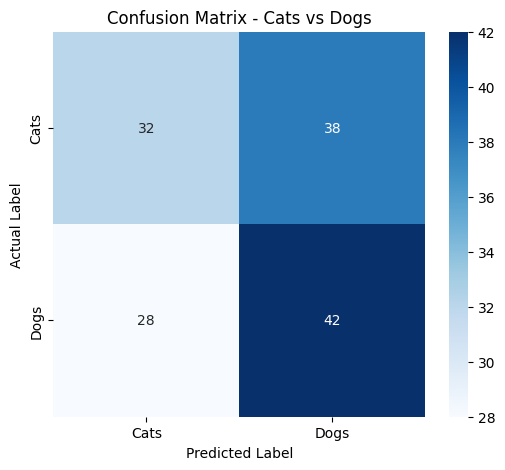

In [21]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Cats", "Dogs"],
    yticklabels=["Cats", "Dogs"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Cats vs Dogs")

plt.show()